In [66]:
!pip -q install factor_analyzer

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy.stats import chi2
from scipy.stats import levene

from statsmodels.multivariate.manova import MANOVA
from statsmodels.formula.api import ols

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity
from factor_analyzer import FactorAnalyzer

# **Part A: Data Preparation and Exploratory Data Analysis**

In [67]:
# Load both datasets
red = pd.read_csv('winequality-red.csv', sep=';')
white = pd.read_csv('winequality-white.csv', sep=';')

red["color"] = "Red"
white["color"] = "White"

# Combine the datasets
wine = pd.concat([red, white], ignore_index=True)

# Make wine into a categorical variable
wine["color"] = pd.Categorical(wine["color"], categories=["Red", "White"])

print("First five observations of combined dataset:")
print(wine.head())

First five observations of combined dataset:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality color  
0      9.4   

In [68]:
# Print dataset structure
print("DATASET STRUCTURE")
wine.info()

# Print number of observations for red and white wine
print("\nObservations by wine color:")
print(wine["color"].value_counts())

print("\nFirst five observations of combined dataset:")
print(wine.head())

DATASET STRUCTURE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   fixed acidity         6497 non-null   float64 
 1   volatile acidity      6497 non-null   float64 
 2   citric acid           6497 non-null   float64 
 3   residual sugar        6497 non-null   float64 
 4   chlorides             6497 non-null   float64 
 5   free sulfur dioxide   6497 non-null   float64 
 6   total sulfur dioxide  6497 non-null   float64 
 7   density               6497 non-null   float64 
 8   pH                    6497 non-null   float64 
 9   sulphates             6497 non-null   float64 
 10  alcohol               6497 non-null   float64 
 11  quality               6497 non-null   int64   
 12  color                 6497 non-null   category
dtypes: category(1), float64(11), int64(1)
memory usage: 615.7 KB

Observations by wine color:


The newly created dataset which has both red and white wine has 6,497 observations, with 4898 white wine and 1599 red wine, and 13 variables, one of which is the newly created color variable.

In [69]:
# Check to see if there are missing values
print("Missing Values in combined dataset:\n")
print(wine.isnull().sum())

# # Check to see if there are duplicate rows
print("\nNumber of exact duplicate rows in combined dataset:\n")
print(wine.duplicated().sum())

Missing Values in combined dataset:

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
color                   0
dtype: int64

Number of exact duplicate rows in combined dataset:

1177


The duplicate rows will not be removed as it is possible for wine to have the same physiochemical characteristics.

In [70]:
# Create quantitative variables (which is all variables except color)
quantitative_vars = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar",
                     "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density",
                     "pH", "sulphates", "alcohol", "quality"]

# Create physiochemical variables by removing quality
physiochemical_vars = quantitative_vars[:-1]

# Checking for univariate outliers using IQR
outlier_results = []
for var in quantitative_vars:
    Q1 = wine[var].quantile(0.25)
    Q3 = wine[var].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound, upper_bound = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    flagged = (wine[var] < lower_bound) | (wine[var] > upper_bound)

    outlier_results.append({
        "Variable": var,
        "Potential Outliers": int(flagged.sum()),
        "Percentage (%)": round(100 * flagged.mean(), 2)
    })

# Print univariate outliers
print("======UNIVARIATE OUTLIERS:======\n")
display(pd.DataFrame(outlier_results))

# Checking for multivariate outliers using Mahalanobis distance
X = wine[physiochemical_vars]
X_standardized = (X - X.mean()) / X.std(ddof=1)

cov_matrix = np.cov(X_standardized, rowvar=False)
inv_cov_matrix = np.linalg.pinv(cov_matrix)
centered = X_standardized.to_numpy()

distances_squared = np.sum(np.dot(centered, inv_cov_matrix) * centered, axis=1)

cutoff = chi2.ppf(0.99, df=len(physiochemical_vars))
multivariate_flags = distances_squared > cutoff

# Print multivariate outliers
print(f"\n======MULTIVARIATE OUTLIERS:======\n")
print(f"\nChi-square cutoff: {round(cutoff, 3)} \n")
print(f"\nPotential multivariate outliers: {int(multivariate_flags.sum())} ({round(100 * multivariate_flags.mean(), 2)}%) \n")

======UNIVARIATE OUTLIERS:======



,Variable,Potential Outliers,Percentage (%)
0,fixed acidity,357,5.49
1,volatile acidity,377,5.80
2,citric acid,509,7.83
3,residual sugar,118,1.82
4,chlorides,286,4.40
5,free sulfur dioxide,62,0.95
6,total sulfur dioxide,10,0.15
7,density,3,0.05
8,pH,73,1.12
9,sulphates,191,2.94



======MULTIVARIATE OUTLIERS:======


Chi-square cutoff: 24.725 


Potential multivariate outliers: 295 (4.54%) 



In [71]:
# Display descriptive statistics of combined dataset
print("DESCRIPTIVE STATISTICS")
print(wine.describe().round(3))

DESCRIPTIVE STATISTICS
       fixed acidity  volatile acidity  citric acid  residual sugar  \
count       6497.000          6497.000     6497.000        6497.000   
mean           7.215             0.340        0.319           5.443   
std            1.296             0.165        0.145           4.758   
min            3.800             0.080        0.000           0.600   
25%            6.400             0.230        0.250           1.800   
50%            7.000             0.290        0.310           3.000   
75%            7.700             0.400        0.390           8.100   
max           15.900             1.580        1.660          65.800   

       chlorides  free sulfur dioxide  total sulfur dioxide   density  \
count   6497.000             6497.000              6497.000  6497.000   
mean       0.056               30.525               115.745     0.995   
std        0.035               17.749                56.522     0.003   
min        0.009                1.000        

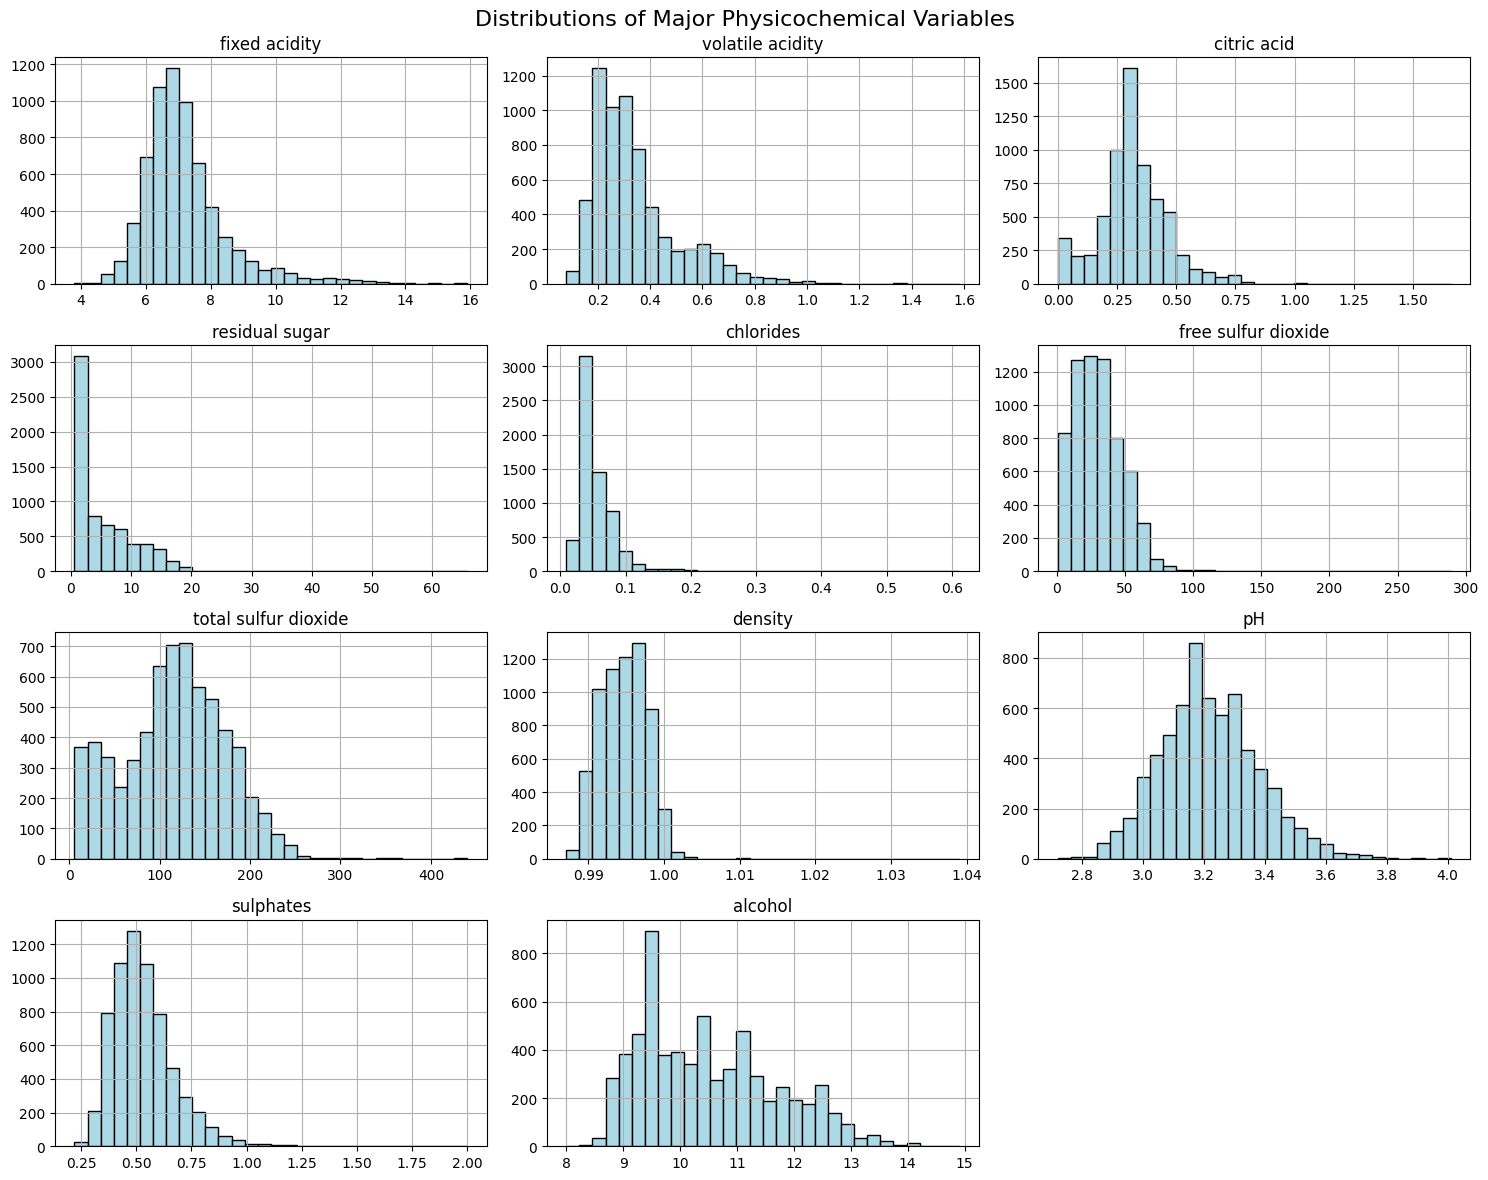

In [72]:
# Create histogram to show distribution of major physiochemical variables

wine[physiochemical_vars].hist(figsize=(15, 12), bins=30, edgecolor="black", color="lightblue")
plt.suptitle("Distributions of Major Physicochemical Variables", fontsize=16)
plt.tight_layout()
plt.show()

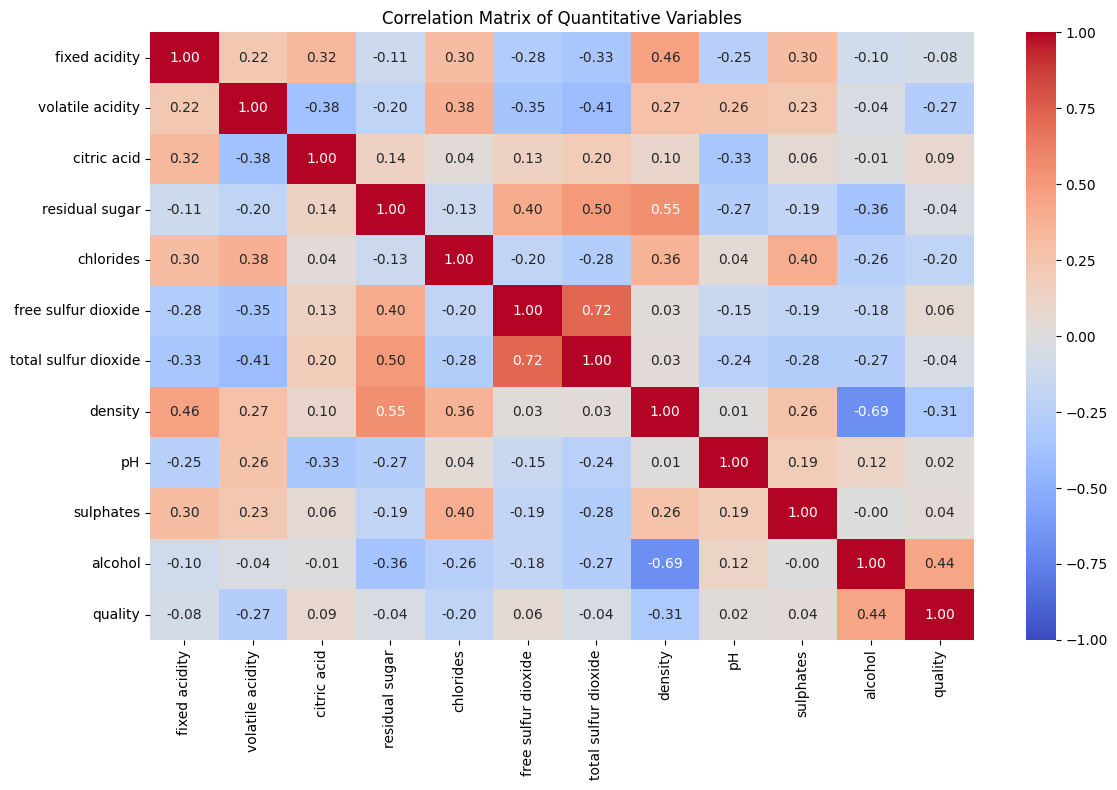

In [73]:
# Create correlation matrix to show Pearson correlation between each quantitative variable
plt.figure(figsize=(12, 8))
correlation_matrix = wine[quantitative_vars].corr(method="pearson")
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Matrix of Quantitative Variables")
plt.tight_layout()
plt.show()

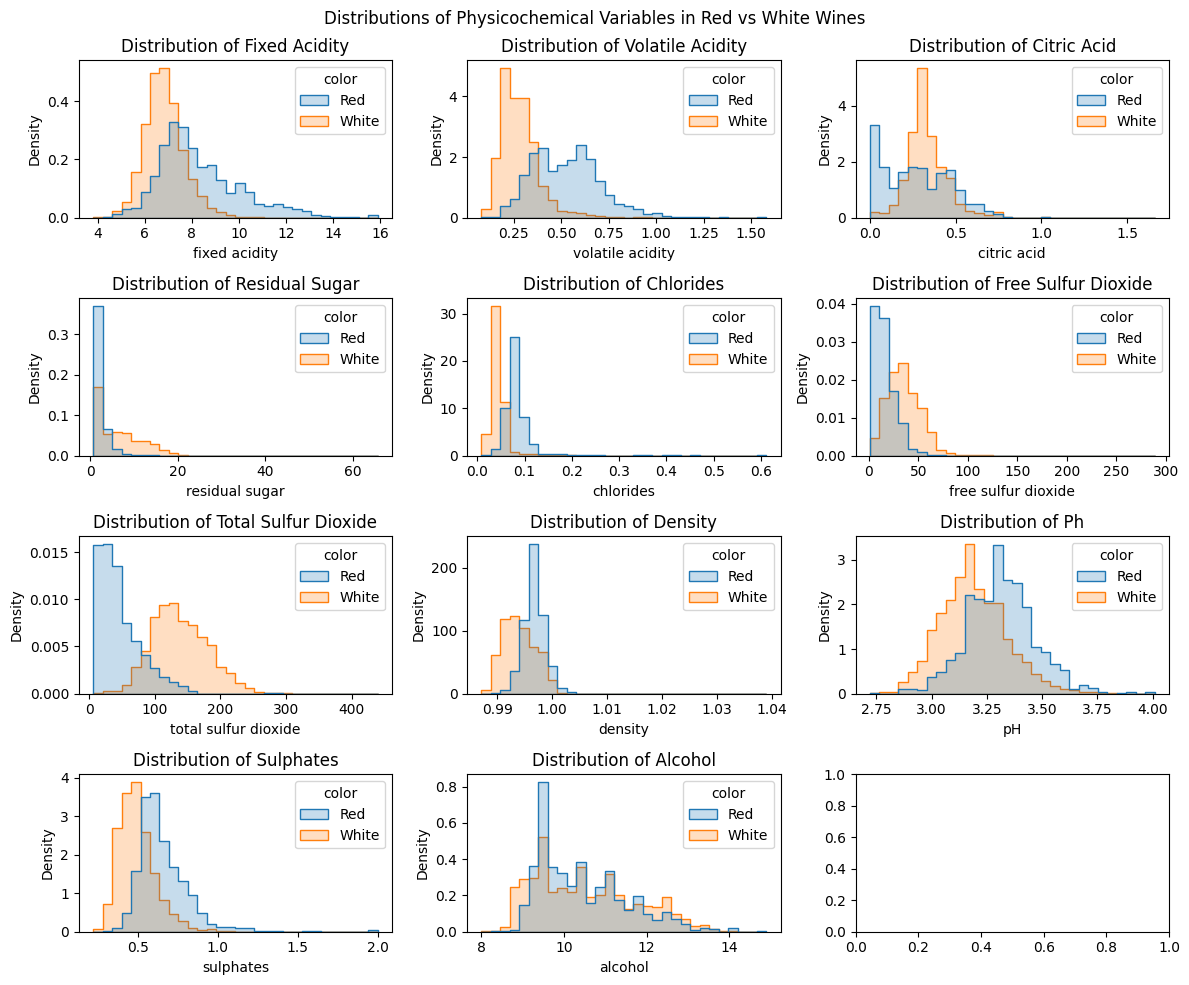

In [74]:
# Histogram to show difference of distribution of variables between red and white wines
fig, axes = plt.subplots(4, 3, figsize=(12, 10))

for ax, var in zip(axes.flat, physiochemical_vars):
    sns.histplot(
        data=wine,
        x=var,
        hue="color",
        bins=30,
        stat="density",
        common_norm=False,
        element="step",
        ax=ax
    )
    ax.set_title(f"Distribution of {var.title()}")

plt.suptitle(
    "Distributions of Physicochemical Variables in Red vs White Wines"
)
plt.tight_layout()
plt.show()

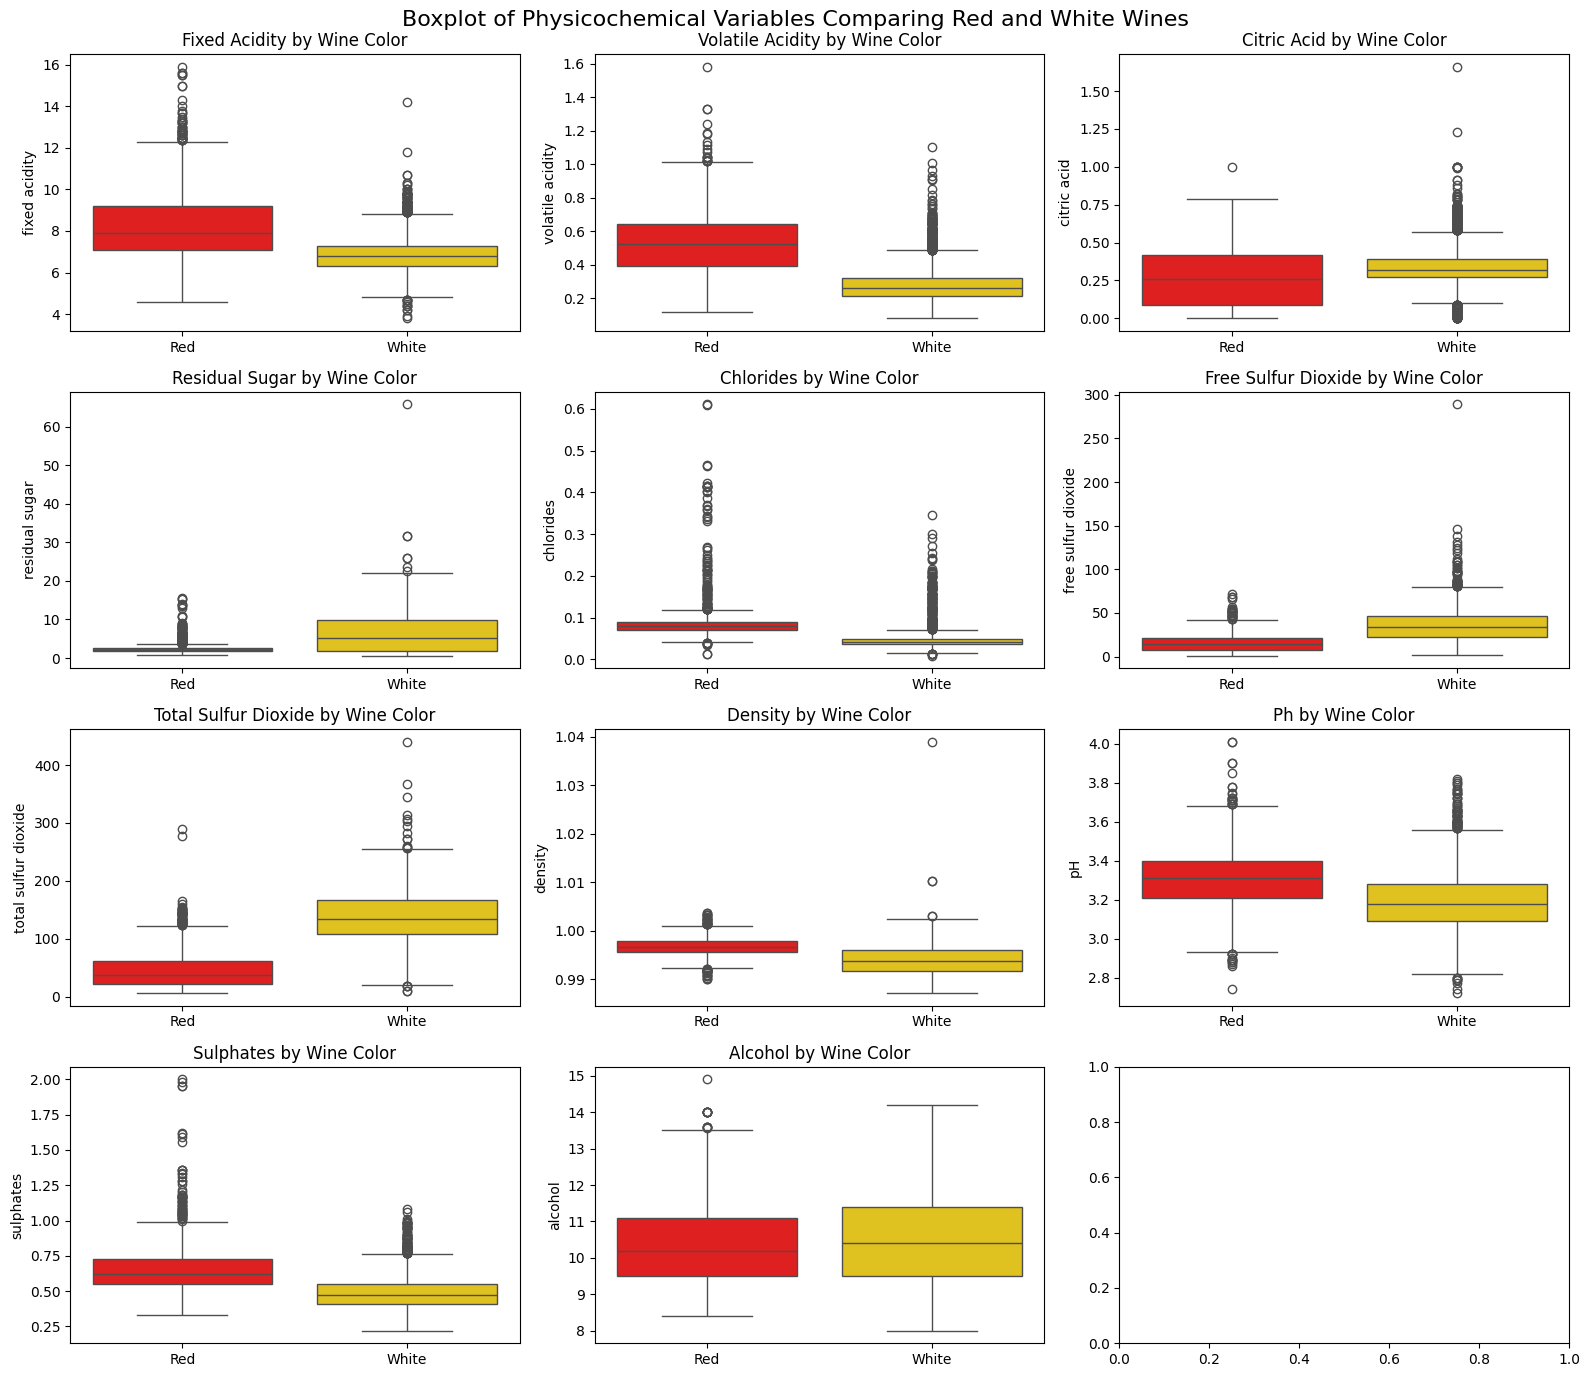

In [75]:
# Boxplot to show difference of distribution of variables between red and white wines

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
for i, var in enumerate(physiochemical_vars):
    sns.boxplot(data=wine, x="color", y=var, hue="color", palette={"Red": "red", "White": "gold"}, ax=axes.flatten()[i], legend=False)
    axes.flatten()[i].set_title(f"{var.title()} by Wine Color")
    axes.flatten()[i].set_xlabel("")
plt.suptitle("Boxplot of Physicochemical Variables Comparing Red and White Wines", fontsize=16)
plt.tight_layout()
plt.show()

* Which variables appear most variable?
The variables which appear the most variable are the ones related to sulfur dioxide, which are 'free sulfur dioxide' and 'total sulfur dioxide'. Free sulfur dioxide has a standard deviation of 17.749 and a minimum of 1 and maximum of 289. Total sulfur dioxide has a standard deviation of 56.522, and a minimum of 6 and maximum of 440.

* Which variables appear strongly correlated?
The variables which appear to be strongly correlated are: total sulfur dioxide and free sulfur dioxide ( r = 0.72), density and alcohol (r = -0.69), and residual sugar and density (r = 0.55).

* Are there noticeable differences between red and white wines?
Yes, just from the graphs it can be seen that their physiochemical characteristics are different. Red wines were shown to typically have higher volatile acidity, chlorides, sulphates, and fixed acidity. Meanwhile, white wines were shown to have higher total sulfur dioxide, free sulfur dioxide, and slightly higher residual sugar.

* Are there potential outliers or unusual observations?
Yes. Using the IQR method showed that there univariate outliers across all variables, with some only having a few and some having hundreds. Mahalanobis distance identified 295 potential multivariate outliers, which is 4.54% of the observations, based on a Chi-square cutoff of 24.72.

* Are there variables that may require special consideration before PCA or EFA?
Yes, it should be noted that the variables are measured on very different scales. For example, chlorides are small fractions, meanwhile total sulfur dioxide can reach up to 440 in value. The physicochemical variables should be standardized prior to PCA and EFA. This is done in order to prevent variables with larger numerical ranges from dominating the variance.

# **Part B – Multivariate Analysis of Variance (MANOVA)**

Research Question

*Do red and white wines differ significantly in their combined physicochemical
characteristics?*


For this analysis:

Independent variable: color

Groups: Red vs. White

Dependent variables: Select at least four physicochemical variables

The chosen physiochemical variables based one the EDA are the following:

* Total Sulfur Dioxide was included as it only had 10 univariate outliers, and it was shown that red wine typically have lower values of total sulfur dioxide, and white wine had higher values of it. As this is strongly correlated with free sulfur dioxide, free sulfur dioxide was excluded to limit redudancy and avoid multicollinearity.

* Alcohol was chosen as it only has 3 univariate outliers. This low outlier frequency makes it suitable for MANOVA. Additionally, since this strongly negatively related with density, density was excluded.

* Residual Sugar was selected as it has a manageable outlier rate of 1.82%. Red wines also have lower residual sugar values compared to white wines. This is moderately related to density, which is no problem as density is already excluded due to alcohol.

* pH was chosen as it only has a outlier rate of 1.12%. Addirionaly, it has very low correlations with the rest of the dataset (the strongest being a weak -0.330 with citric acid), meaning it can provide unique variance to the model.



**Hypotheses:**

H0 : The mean vector of the alcohol, total sulfur dioxide, alcohol, residual sugar, and pH variables is the same for red and white wines.

H1 : The mean vectors differ between red and white wines.

In [76]:
# MANOVA dataset for selected variables
wine_manova = wine[['color', 'total sulfur dioxide', 'alcohol', 'residual sugar', 'pH']].copy()
wine_manova.columns = ['color', 'total_sulfur_dioxide', 'alcohol', 'residual_sugar', 'ph']
manova_vars = wine_manova.columns[1:]

# Assessing MANOVA assumptions
print("=====MANOVA assumptions:=====\n")

# Levene's Test to assess homogeneity of variances
print("\nHomogeneity of Variances (Levene's Test):\n")
for var in manova_vars:
    stat, p = levene(wine_manova[wine_manova['color'] == 'Red'][var],
                     wine_manova[wine_manova['color'] == 'White'][var])
    print(f"{var:>20}: W-stat = {stat:8.3f}, p-value = {p:.4e}")

#
print("\nRelationships Among Dependent Variables for MANOVA (Pearson Correlation):\n")
display(wine_manova[manova_vars].corr().round(3))

X_manova = wine_manova[manova_vars]
X_standardized = (X_manova - X_manova.mean()) / X_manova.std(ddof=1)
cov_matrix = np.cov(X_standardized, rowvar=False)
inv_cov_matrix = np.linalg.pinv(cov_matrix)
centered = X_standardized.to_numpy()
distances_squared = np.sum(np.dot(centered, inv_cov_matrix) * centered, axis=1)

cutoff = chi2.ppf(0.99, df=len(manova_vars))
multivariate_outliers = (distances_squared > cutoff).sum()
print(f"Number of observations exceeding Chi-square cutoff ({cutoff:.2f}): {multivariate_outliers}")

print("\n=====MANOVA=====\n")
ma = MANOVA.from_formula('total_sulfur_dioxide + alcohol + residual_sugar + ph ~ color', data=wine_manova)
manova_results = ma.mv_test()

display(manova_results.results['color']['stat'])

pillais_value = manova_results.results['color']['stat'].loc["Pillai's trace", "Value"]
f_value = manova_results.results['color']['stat'].loc["Pillai's trace", "F Value"]
num_df = manova_results.results['color']['stat'].loc["Pillai's trace", "Num DF"]
den_df = manova_results.results['color']['stat'].loc["Pillai's trace", "Den DF"]
p_value = manova_results.results['color']['stat'].loc["Pillai's trace", "Pr > F"]

print("\n=====REPORTING PILLAI'S TRACE=====\n")
print(f"\nTest Statistic (Pillai's Trace): {pillais_value:.4f}")
print(f"\nF-value:                         {f_value:.4f}")
print(f"\nDegrees of Freedom (Num, Den):   ({num_df}, {den_df})")
print(f"\np-value:                         {p_value:.4e}")
print(f"\nMultivariate Effect Size (η²):   {pillais_value:.4f}")



=====MANOVA assumptions:=====


Homogeneity of Variances (Levene's Test):

total_sulfur_dioxide: W-stat =  181.381, p-value = 8.5065e-41
             alcohol: W-stat =   72.785, p-value = 1.7802e-17
      residual_sugar: W-stat = 1867.544, p-value = 0.0000e+00
                  ph: W-stat =    0.482, p-value = 4.8770e-01

Relationships Among Dependent Variables for MANOVA (Pearson Correlation):



,total_sulfur_dioxide,alcohol,residual_sugar,ph
total_sulfur_dioxide,1.000,-0.266,0.495,-0.238
alcohol,-0.266,1.000,-0.359,0.121
residual_sugar,0.495,-0.359,1.000,-0.267
ph,-0.238,0.121,-0.267,1.000


Number of observations exceeding Chi-square cutoff (13.28): 69

=====MANOVA=====



,Value,Num DF,Den DF,F Value,Pr > F
Wilks' lambda,0.423616,4,6492.0,2208.301071,0.0
Pillai's trace,0.576384,4.0,6492.0,2208.301071,0.0
Hotelling-Lawley trace,1.360629,4,6492.0,2208.301071,0.0
Roy's greatest root,1.360629,4,6492,2208.301071,0.0



=====REPORTING PILLAI'S TRACE=====


Test Statistic (Pillai's Trace): 0.5764

F-value:                         2208.3011

Degrees of Freedom (Num, Den):   (4.0, 6492.0)

p-value:                         0.0000e+00

Multivariate Effect Size (η²):   0.5764


The Levene's test should that the equal-variance assumption is violated for total sulfur dioxide, alcohol, and residual sugar, but not for pH.

The correlations among the four dependent variables are:

Total sulfur dioxide and residual sugar: \(r=0.495\)
Alcohol and residual sugar: \(r=-0.359\)
Total sulfur dioxide and alcohol: \(r=-0.266\)
Residual sugar and pH: \(r=-0.267\)
Total sulfur dioxide and pH: \(r=-0.238\)
Alcohol and pH: \(r=0.121\)

These are mostly weak-to-moderate relationships, indicating that while the dependent variables are related, they are not measuring exactly the same characteristic.

In [77]:
# Create follow-up ANOVA
print("\n=====UNIVARIATE ANOVAS=====\n")

for var in manova_vars:

    model = ols(f'{var} ~ color', data=wine_manova).fit()
    aov_table = sm.stats.anova_lm(model, typ=2)

    sum_sq_treatment = aov_table['sum_sq'].iloc[0]
    sum_sq_residual = aov_table['sum_sq'].iloc[1]
    f_val = aov_table['F'].iloc[0]
    p_val = aov_table['PR(>F)'].iloc[0]

    eta_squared = sum_sq_treatment / (sum_sq_treatment + sum_sq_residual)

    print(f"\nDependent Variable: {var.replace('_', ' ').upper()}")
    print(f"  F-value:     {f_val:.4f}")
    print(f"  p-value:     {p_val:.4e}")
    print(f"  Effect Size: {eta_squared:.4f} (Eta-squared)")


=====UNIVARIATE ANOVAS=====


Dependent Variable: TOTAL SULFUR DIOXIDE
  F-value:     6252.7956
  p-value:     0.0000e+00
  Effect Size: 0.4905 (Eta-squared)

Dependent Variable: ALCOHOL
  F-value:     7.0677
  p-value:     7.8679e-03
  Effect Size: 0.0011 (Eta-squared)

Dependent Variable: RESIDUAL SUGAR
  F-value:     899.7663
  p-value:     2.9594e-185
  Effect Size: 0.1217 (Eta-squared)

Dependent Variable: PH
  F-value:     789.0495
  p-value:     5.9233e-164
  Effect Size: 0.1083 (Eta-squared)


### **Required interpretation**

Answer the question:

*Are red and white wines significantly different when their physicochemical
characteristics are considered simultaneously?*

The MANOVA provides indicates that red and white wines significantly different when the chosen physiochemical variables (total sulfur dioxide, alcohol, residual sugar, pH) are considered simultaneously. Therefore, we reject the null hypothesis and accept the alternative hypothesis.

This means that wine color is associated with a statistically significant difference in the combined physicochemical profile.

Further ANOVA analysis revealed that total sulfur dioxide has the largest effect size  of 0.4905. This means that wine color accounts for a substantial amount of the variance in total sulfur dioxide. Additionally, residual sugar and pH also show meaningful group differences, with effect sizes of 0.1217 and 0.1083 respectively.

In the ANOVA, alcohol is statistically significant, but its effect size is extremely small, only 0.0011. This is to be expected as due to large number of observations, a very small difference can still lead to statistical significance. Therefore, alcohol should not be considered as an important practical contributor to the difference in red and white wine.

# **Part C – Principal Component Analysis (PCA)**

**Examine the correlation structure**
As shown in the EDA, several variables share moderate-to-strong correlations (e.g., total sulfur dioxide and free sulfur dioxide ( r = 0.72), density and alcohol (r = -0.69), and residual sugar and density (r = 0.55)). This underlying correlation structure indicates that shared variance exists, which makes PCA an appropriate technique in order to reduce dimensionality of the model.


* Are there variables that may require special consideration before PCA or EFA?
Yes, it should be noted that the variables are measured on very different scales. For example, chlorides are small fractions, meanwhile total sulfur dioxide can reach up to 440 in value. The physicochemical variables should be standardized prior to PCA and EFA. This is done in order to prevent variables with larger numerical ranges from dominating the variance.

**Standardize the variables**
Standardization  is required before running PCA. Because as stated in the EDA,variables are measured on very different scales. Since PCA identifies directions of maximum variance, variables which are measured on larger numeric scales, total sulfur dioxide, will artificially dominate the principal components if the data is left unstandardized.

In [78]:
# Standardize the variables
X_pca = wine[physiochemical_vars]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca)

In [79]:
# Determine number of components
pca_full = PCA()
pca_full.fit(X_scaled)

# Report number of components
print("Number of PCA components:", pca_full.n_components_)

# Calculate eigenvalues for components
eigenvalues = pca_full.explained_variance_

# Calculate proportion of variance for components
prop_variance = pca_full.explained_variance_ratio_

# Calculate cumulative variance for components
cml_variance = np.cumsum(prop_variance)

# Insert PCA results into one data frame
pca_results_df = pd.DataFrame({
    'Component': [f'PC{i+1}' for i in range(len(eigenvalues))],
    'Eigenvalue': eigenvalues,
    'Proportion of Variance': prop_variance,
    'Cumulative Variance': cml_variance
})

display(pca_results_df.round(4))

# Extract Loadings for the components
pca_loadings = pd.DataFrame(
    pca_full.components_.T,
    columns=[f'PC{i+1}' for i in range(pca_full.n_components_)],
    index=physiochemical_vars
)

display(pca_loadings.round(3))

Number of PCA components: 11


,Component,Eigenvalue,Proportion of Variance,Cumulative Variance
0,PC1,3.0303,0.2754,0.2754
1,PC2,2.4942,0.2267,0.5022
2,PC3,1.5566,0.1415,0.6436
3,PC4,0.9707,0.0882,0.7319
4,PC5,0.7200,0.0654,0.7973
5,PC6,0.6074,0.0552,0.8525
6,PC7,0.5232,0.0476,0.9001
7,PC8,0.5016,0.0456,0.9457
8,PC9,0.3371,0.0306,0.9763
9,PC10,0.2277,0.0207,0.9970


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11
fixed acidity,-0.239,0.336,0.434,-0.164,-0.147,0.205,-0.283,-0.401,-0.344,0.281,-0.335
volatile acidity,-0.381,0.118,-0.307,-0.213,0.151,0.492,-0.389,0.087,0.497,-0.152,-0.085
citric acid,0.152,0.183,0.591,0.264,-0.155,-0.228,-0.381,0.293,0.403,-0.234,0.001
residual sugar,0.346,0.330,-0.165,-0.167,-0.353,0.233,0.218,0.525,-0.108,0.001,-0.450
chlorides,-0.290,0.315,-0.017,0.245,0.614,-0.161,-0.046,0.472,-0.296,0.197,-0.043
free sulfur dioxide,0.431,0.072,-0.134,0.357,0.224,0.340,-0.299,-0.208,-0.367,-0.480,0.000
total sulfur dioxide,0.487,0.087,-0.107,0.208,0.158,0.151,-0.139,-0.129,0.321,0.714,0.063
density,-0.045,0.584,-0.176,-0.073,-0.307,-0.019,-0.047,-0.005,-0.113,0.004,0.715
pH,-0.219,-0.156,-0.455,0.415,-0.453,-0.297,-0.419,0.029,-0.128,0.141,-0.206
sulphates,-0.294,0.192,0.070,0.641,-0.137,0.297,0.525,-0.166,0.208,-0.046,-0.077


While there were 11 components produced, only the first three components eigenvalues greater than 1. The first three components have a cumulative percentage of 64.36%. This means that these three components explain almost two-thirds of the standardized variance.



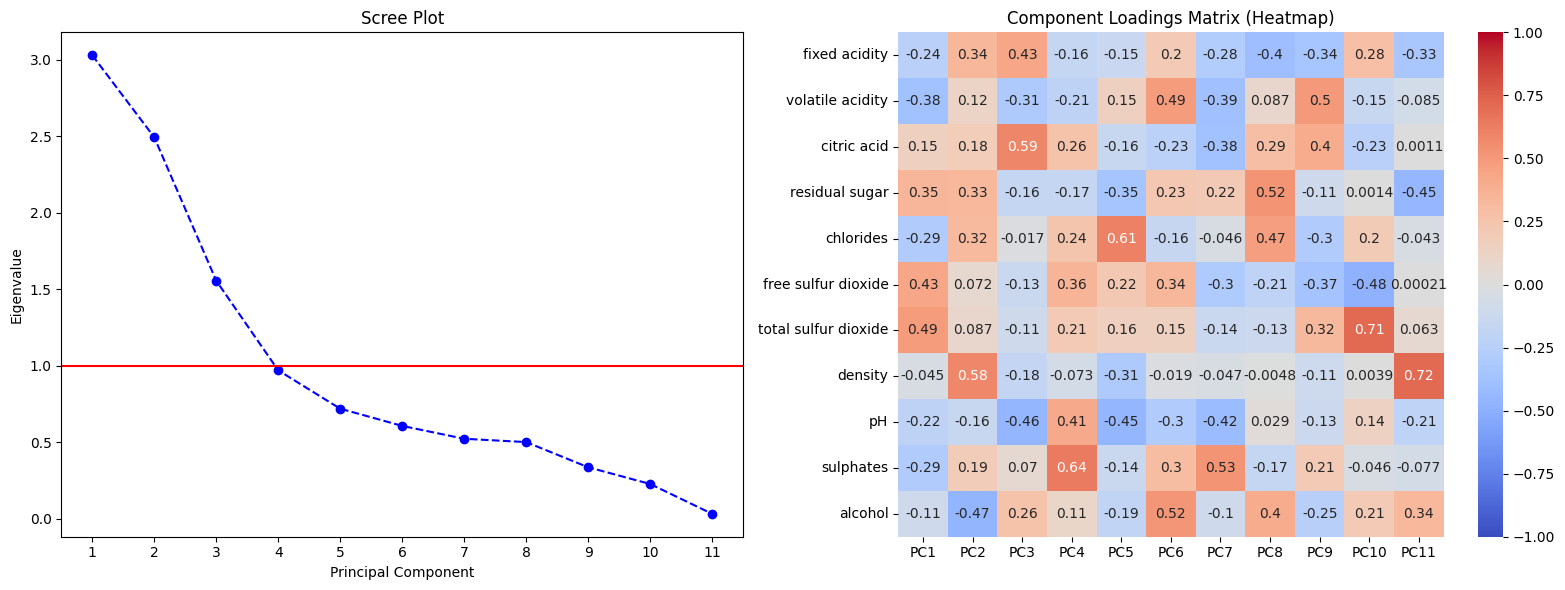

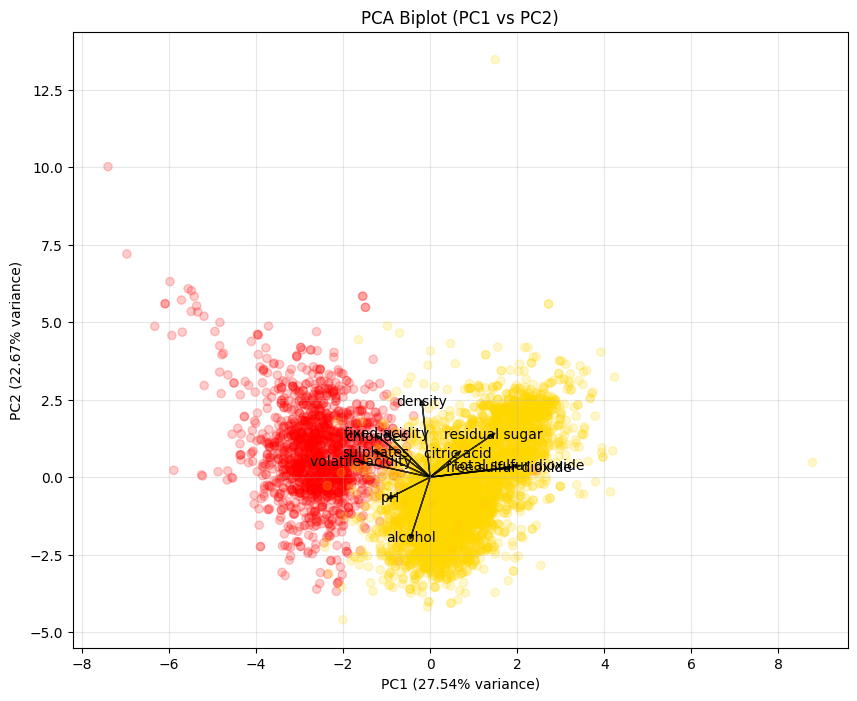

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Visualize the PCA using scree plot
axes[0].plot(range(1, len(eigenvalues) + 1), eigenvalues, marker='o', linestyle='--', color='b')
axes[0].axhline(y=1, color='r', linestyle='-')
axes[0].set_title('Scree Plot')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Eigenvalue')
axes[0].set_xticks(range(1, len(eigenvalues) + 1))

# Visualize the PCA using loading plot
sns.heatmap(pca_loadings, annot=True, cmap='coolwarm', center=0, ax=axes[1], vmin=-1, vmax=1)
axes[1].set_title('Component Loadings Matrix (Heatmap)')

plt.tight_layout()
plt.show()

# Biplot to visualize PC1 vs P2
pca_2d = pca_full.transform(X_scaled)[:, :2]
plt.figure(figsize=(10, 8))
plt.scatter(pca_2d[:, 0], pca_2d[:, 1], alpha=0.2, c=wine['color'].map({'Red': 'red', 'White': 'gold'}))

# Add the loading vectors
for i, var in enumerate(physiochemical_vars):
    plt.arrow(0, 0, pca_loadings.iloc[i, 0]*4, pca_loadings.iloc[i, 1]*4,
              color='black', alpha=0.8, head_width=0.1)
    plt.text(pca_loadings.iloc[i, 0]*4.2, pca_loadings.iloc[i, 1]*4.2, var, color='black', ha='center', va='center')

plt.title('PCA Biplot (PC1 vs PC2)')
plt.xlabel(f"PC1 ({prop_variance[0]:.2%} variance)")
plt.ylabel(f"PC2 ({prop_variance[1]:.2%} variance)")
plt.grid(True, alpha=0.3)
plt.show()

### **Interpret the components**

**PC1**

PC1 explains 27.54% of the total variance, with its strongest positive loadings including the following variables: total sulfur dioxide (0.487), free sulfur dioxide (0.431), and residual sugar (0.346). It also has strong negative loadings for the following variables: volatile acidity (-0.381),chlorides (-0.290), and sulphates (-0.294).

Therefore, PC1 represents a sulfur dioxide and broader chemical-composition dimension, and should be named **sulfur dioxide and chemical composition**.

Additionally, importance of sulfur dioxide in PC1 agrees with Part A, where free and total sulfur dioxide had their strongest correlation.

**PC2**

PC2 explains 22.67% of the variance,  with its strongest positive loadings including the following variables: density (0.584), and residual sugar (0.33). It also has a moderately strong negative loading in alcohol (-0.465).

Therefore, PC2 represents as a density–sugar–alcohol dimension, and should be named **density, residual sugar, and alcohol**.

Additionally, the negative alcohol loading agrees with the strong negative correlation between density and alcohol found in Part A. Both density and residual sugar having positive loading also agrees with their positive correlation in Part A.

**PC3**

PC3 explains 14.15% of the variance, with its strongest positive loadings including the following variables: citric acid (0.591) and fixed acidity (0.434). It also has strong negative loadings for the following variables: pH (-0.455), and volatile acididty (-0.307).

Therefore, PC3 represents differences associated with citric acid, fixed acidity, pH, and volatile acidity, and should be named **acid composition**.

### **Required interpretation**

Discuss:

*How many components are sufficient to summarize the physicochemical characteristics of the wines, and how much information is retained?*

Avoid simply stating “three components were retained.” Instead, explain what the components represent in terms of wine characteristics.

The PCA reduces the 11 physicochemical measurements into three components, retaining 64.36% of the total standardized variance.

This three components represent the following:
1. Sulfur dioxide and chemical composition
2. Density, residual sugar, and alcohol
3. Acid composition

# **Part D – Exploratory Factor Analysis (EFA)**

In [81]:
# Assess factorability using KMO and Bartlett's Test
kmo_all, kmo_model = calculate_kmo(X_scaled)
print(f"KMO: {kmo_model:.3f}")

chi_square_value, p_value = calculate_bartlett_sphericity(X_scaled)
print(f"Bartlett's Test: Chi-Square = {chi_square_value:.2f}, p-value = {p_value:.4e}")

KMO: 0.405
Bartlett's Test: Chi-Square = 37094.62, p-value = 0.0000e+00


The KMO value is 0.405, which is relatively and low and is an indication of weak overall sampling adequacy for factor analysis.

On the other, Bartlett's test is highly significant, with chi squared =37094.62,and p<.001.

This means that the correlation matrix is not an identity matrix, and that statistically significant relationships exist among the physicochemical variables.

Bartlett's test supports factorability, but the low KMO indicates that the factor solution should be analyzed cautiously and not taken at face-value.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


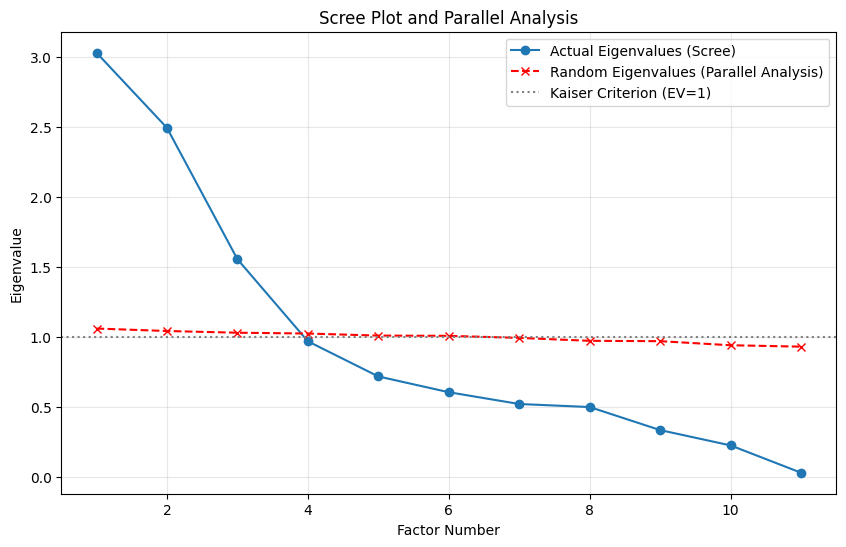

Eigenvalues of the factors:
Factor 1: Actual EV = 3.030 | Random EV = 1.062
Factor 2: Actual EV = 2.494 | Random EV = 1.044
Factor 3: Actual EV = 1.556 | Random EV = 1.032
Factor 4: Actual EV = 0.971 | Random EV = 1.026
Factor 5: Actual EV = 0.720 | Random EV = 1.011
Factor 6: Actual EV = 0.607 | Random EV = 1.010
Factor 7: Actual EV = 0.523 | Random EV = 0.995
Factor 8: Actual EV = 0.502 | Random EV = 0.974
Factor 9: Actual EV = 0.337 | Random EV = 0.972
Factor 10: Actual EV = 0.228 | Random EV = 0.942
Factor 11: Actual EV = 0.033 | Random EV = 0.932


In [82]:
# Get actual eigenvalues
fa = FactorAnalyzer(n_factors=X_scaled.shape[1], rotation=None)
fa.fit(X_scaled)
ev, v = fa.get_eigenvalues()

# Parallel Analysis (simulate random data of the same shape)
np.random.seed(42)
random_data = np.random.normal(size=X_scaled.shape)
fa_random = FactorAnalyzer(n_factors=X_scaled.shape[1], rotation=None)
fa_random.fit(random_data)
ev_random, v_random = fa_random.get_eigenvalues()

# Create scree plot for parallel analysis
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(ev) + 1), ev, marker='o', label='Actual Eigenvalues (Scree)')
plt.plot(range(1, len(ev_random) + 1), ev_random, marker='x', linestyle='--', color='red', label='Random Eigenvalues (Parallel Analysis)')
plt.axhline(y=1, color='gray', linestyle=':', label='Kaiser Criterion (EV=1)')

plt.title('Scree Plot and Parallel Analysis')
plt.xlabel('Factor Number')
plt.ylabel('Eigenvalue')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Eigenvalues of the factors:")
for i in range(11):
    print(f"Factor {i+1}: Actual EV = {ev[i]:.3f} | Random EV = {ev_random[i]:.3f}")

### **Determine the Number of Factors**

It can be see that the Eigenvalues (Kaiser Criterion), only the first three factors have actual eigenvalues greater than 1.0 (3.030, 2.494, and 1.556), and that the fourth factor was only 0.971. Meanwhile in the Parallel Analysis and Scree Plot, it can be seen that comparing the data's actual eigenvalues to those generated from random simulated data shows that the actual eigenvalues drop below the random eigenvalues at the fourth factor. Based on all of these, it was determined that using **3 factors** is the most appropriate decision.

**Decision:** Based on converging evidence from the Kaiser criterion, the scree plot elbow, and parallel analysis, retaining **3 factors** is the most statistically sound decision[cite: 27].

### **Select an Extraction Method**

**Minimum Residuals (minres)** was chosen as the factor extraction method. MinRes is effective at minimizing the residual correlation matrix and while still being robust, especially  compared to Maximum Likelihood (ML), when data mildly violates strict multivariate normality.

### **Select a Rotation Method**
The selected rotation metho was **Promax**, which is an oblique rotation method. Oblique rotations allow the underlying latent factors to correlate with one another. Since the physicochemical properties of wine are inherently interrelated through biological and chemical processes, it should not eb assumed the latent factors are completely independent.

In [83]:
print("\n=====EFA LOADINGS AND FACTOR LOADINGS=====\n")

# Fit the EFA model with 3 factors, minres extraction, and promax rotation
efa = FactorAnalyzer(n_factors=3, rotation='promax', method='minres')
efa.fit(X_scaled)

# Insert the loadings into a dataframe
efa_loadings = pd.DataFrame(efa.loadings_, index=physiochemical_vars,
                            columns=['Factor 1', 'Factor 2', 'Factor 3'])

# Insert the communalities and uniqueness into a dataframe
efa_variance = pd.DataFrame({
    'Communalities': efa.get_communalities(),
    'Uniqueness': efa.get_uniquenesses()
}, index=physiochemical_vars)

print("\nFACTOR LOADINGS (Values > |0.4| are strong):")
display(efa_loadings.round(3))

print("\nCOMMUNALITIES & UNIQUENESS:")
display(efa_variance.round(3))


=====EFA LOADINGS AND FACTOR LOADINGS=====


FACTOR LOADINGS (Values > |0.4| are strong):


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,Factor 1,Factor 2,Factor 3
fixed acidity,0.745,0.068,0.560
volatile acidity,0.490,0.165,-0.415
citric acid,0.091,-0.053,0.738
residual sugar,-0.338,0.619,0.064
chlorides,0.527,0.237,-0.018
free sulfur dioxide,-0.599,0.297,0.056
total sulfur dioxide,-0.724,0.360,0.106
density,0.423,0.952,-0.017
pH,0.067,-0.025,-0.514
sulphates,0.472,0.067,0.022



COMMUNALITIES & UNIQUENESS:


,Communalities,Uniqueness
fixed acidity,0.874,0.126
volatile acidity,0.440,0.560
citric acid,0.556,0.444
residual sugar,0.502,0.498
chlorides,0.335,0.665
free sulfur dioxide,0.450,0.550
total sulfur dioxide,0.665,0.335
density,1.085,-0.085
pH,0.270,0.730
sulphates,0.228,0.772


### **Interpret the factors**

Give each retained factor a meaningful name based on the variables that load highly on it.


**Factor 1**

Highest Loadings:

* Fixed acidity: 0.745
* Total sulfur dioxide: -0.724
* Free sulfur dioxide: -0.599
* Chlorides: 0.527
* Volatile acidity: 0.490
* Sulphates: 0.472

This factor represents the pattern involving acidity-related variables and sulfur dioxide variables. Therefore, it should be called **acidity–sulfur dioxide dimension**.

**Factor 2**

Highest Loadings:

* Density: 0.952
* Alcohol: -0.705
* Residual sugar: 0.619

This factor should be called **density–sugar–alcohol dimension**.

This factor also strongly agrees with the EDA and PCA. All three analyses identify density, residual sugar, and alcohol as a common pattern.

**Factor 3**

Highest Loadings:

* Citric Acid: 0.738
* Fixed acidity: 0.560
* pH: -0.514
* Volatile acidity: -0.415

This factor represents a common pattern among citric acid, fixed acidity, pH, and volatile acidity. Therefore it should be called **acid composition dimension**.

## **Required interpretation**

Answer:

What underlying dimensions of wine physicochemical characteristics are revealed by the factor analysis?

Your factor names must be supported by the observed variables.

The three underlying dimensions of physiochemical characteristics revealed by the EFA are:

* The acidity acidity–sulfur dioxide dimension, which has the variables: fixed acidity, total sulfur dioxide, free sulfur dioxide, chlorides, volatile acidity, and sulphates.

* The density–sugar–alcohol dimension, which has the variables: density, alcohol, and residual sugar.

* The acid composition dimesion, which has the variables: citric acid, fixed acidity, pH: -0.514, and volatile acidity.

# **Part E – Integrated Interpretation**

The results from Parts A–D provide complementary evidence about the physicochemical structure of the wine dataset.

Part A established that the physiochemically variables are meaningfully related. The strongest relationships found were between free and total sulfur dioxide (r=0.72), density and alcohol (r=-0.69), and residual sugar and density (r=0.55). The results from this EDA showed that physiochemical characteristics contain shared information rather than behaving independently. This means that when they should be analyzed together when considering their relationship with wine color.

The MANOVA showed that red and white wines have significantly different combined physicochemical profiles. The specific variables used for this MANOVA analysis are: total sulfur dioxide, alcohol, residual sugar, and pH. The follow-up ANOVA analyses showed that total sulfur dioxide had the largest effect size, while residual sugar and pH also had meaningful effects. Alcohol was statistically significant but only had a very small effect size. Therefore, it can be said that the difference between red and white wines is associated with differences in specific aspects of their composition rather than a large difference in every selected variable.

The PCA in Part C showed that three components explain 64.36% of the total standardized variance. PC1, named sulfur dioxide and chemical composition, includes total and free sulfur dioxide, residual sugar, volatile acidity, chlorides, and sulphates. PC2, named density, residual sugar, and alcohol, involves density, residual sugar, and alcohol, while PC3, named acid composition, consists of citric acid, fixed acidity, pH, and volatile acidity.

In Part D, the EFA also supported a supported a three-factor structure, similar to the three components in PCA. Although it should be noted that it has a low KMO value meaning results should be interpreted cautiously. Factor 1, named acidity–sulfur dioxide dimension, includes fixed acidity, total and free sulfur dioxide, chlorides, volatile acidity, and sulphates. Factor 2, named density–sugar–alcohol dimension, involves density, alcohol, and residual sugar, while Factor 3, named acid composition dimension, consists of citric acid, fixed acidity, pH, and volatile acidity.

The strongest commonality between PCA and EFA can be seen in the density–sugar–alcohol relationship. PCA's PC2 has a density loading of 0.584 and an alcohol loading of -0.465, while EFA Factor 2 has a very strong density loading of 0.952, a residual sugar loading of 0.619, and an alcohol loading of -0.705. Additionally, in the EDA density has a moderately strong positive correlation with residual sugar, and moderately strong negative correlation with alcohol. This consistency indicates that the relationship among density, residual sugar, and alcohol is one of the underlying patterns in the dataset.

Another recurring feature across the analyses is sulfure dioxide. Free sulfur dioxide and total sulfur dioxide have a strong correlation that was shown in Part A, it contributes strongly to PC1 in Part C, and have substantial loadings on Factor 1 in Part D. This indicates that sulfur dioxide measurements represents a significant source of shared variation among the wines.

Acidity is also identified in PCA and EFA. Citric acid, fixed acidity, pH, and volatile acidity contribute strongly to both PC3 and Factor 3. Therefore, the acidity-related structure is not limited to a single variable but reflects relationships among several chemical measurements.

However, it should be said that this does mean that PCA and EFA produced the same type of result. To start, PCA is a method that reduces dimensionality, while EFA indetifies factors responsible for shared correlations. The similarity of the results from these two only serves to strengthen the understanding of recurring relationships.

Therefore, all together the analyses tell a consistent overall story. It can be seen that there are differences in the physiochemical profile of the red and white wines. Additionally, variation within the wines can be summarized by several recurring chemical dimensions. The most notable of these include sulfur dioxide, density–residual sugar–alcohol, and acidity.

The analysis also has several limitations. Firstly, the data are observational, so the results indicate associations rather than causal relationships. Additionally, the number of observations for white wines is three times as much a number of obsercations for red wines. There were also several univariate outliers and potential multivariate outliers identified. In addition, the low KMO value of 0.405 suggests that the EFA is relatively weak. Also, the resulting communality greater than one for density also indicates that the EFA estimates should be interpreted cautiously.
